In [1]:
using LatticeDiracOperators
using LatticeQCD
using Gaugefields
using Wilsonloop
using LMP
using LinearAlgebra

[ Info: Precompiling LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018]
[ Info: Skipping precompilation since __precompile__(false). Importing LMP [a75e356b-bbea-40ef-9c9d-31e1efba0018].
┌ Warning: Error requiring `Plots` from `LatticeQCD`
│   exception =
│    LoadError: ArgumentError: Package LatticeQCD does not have Plots in its dependencies:
│    - You may have a partially installed environment. Try `Pkg.instantiate()`
│      to ensure all packages in the environment are installed.
│    - Or, if you have LatticeQCD checked out for development and have
│      added Plots as a dependency but haven't updated your primary
│      environment's manifest file, try `Pkg.resolve()`.
│    - Otherwise you may need to report an issue with LatticeQCD
│    Stacktrace:
│      [1] macro expansion
│        @ .\loading.jl:1839 [inlined]
│      [2] macro expansion
│        @ .\lock.jl:267 [inlined]
│      [3] __require(into::Module, mod::Symbol)
│        @ Base .\loading.jl:1816
│      [4] #invoke_in_world#3


In [2]:
NX = 8
NY = 8
NZ = 8
NT = 16
Nwing = 0
Dim = 4
NC = 3
U = Initialize_4DGaugefields(NC,Nwing,NX,NY,NZ,NT,condition = "hot")
x = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(x)
t = Initialize_pseudofermion_fields(U[1],"Wilson",nowing=true)
gauss_distribution_fermion!(t)
x=x/sqrt(norm2(x))
t=t/sqrt(norm2(t))

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[0.0030214098805512023 - 0.0008872137368185427im -0.0017522845268779837 - 0.0007954214104108878im … -0.0034095198801450495 - 0.003425002352207728im -0.00027341575586980685 + 0.001692292644737707im; -0.0008072605176904666 - 0.0005389834648509778im -0.0003380536806067677 + 0.0030409476264232254im … 0.0014291234452363754 + 0.0014049053648882753im 0.0015899801159449418 + 0.00038001462767126373im; 8.38206757595617e-5 - 0.00019479258815847123im -0.002806074686523607 - 0.0001246707494583745im … -0.0016907666496026727 + 0.0015046285566157034im -0.00341438848040772 - 0.0003985728229260022im;;; 0.001563480635399254 - 0.0020811891364895703im -0.0022772276999990437 + 0.0008839288830467563im … -0.0010636648200815684 + 0.0020793656903401727im 0.0001462126742647949 - 0.0013640150547581129im; -0.003929326168491955 - 0.0018415219982768785im 0.0026365863321848888 - 0.0009241090237706396im … -0.001980582809230785 - 0.0011558760776

In [3]:
P=Onestep()
e=0.1
hop=Hopping_operator(U,P)
W1=Generate_weight(hop)*e
W2=Generate_weight(hop)*e
W3=Generate_weight(hop)*e
W4=Generate_weight(hop)*e
W5=Generate_weight(hop)*e
W6=Generate_weight(hop)*e



9-element Vector{Spin_matrix}:
 [0.07779835090124729 + 0.0im 0.060567796700950596 + 0.0im -0.09940390723455109 + 0.0im 0.09357631929194875 + 0.0im; 0.01857033867082158 + 0.0im -0.1455338262380379 + 0.0im 0.061687082716509516 + 0.0im -0.010411452897074541 + 0.0im; 0.10065420882799268 + 0.0im 0.06658521406443675 + 0.0im 0.1871709182824226 + 0.0im -0.1542156385816844 + 0.0im; 0.11276855489972336 + 0.0im -0.03942186999903416 + 0.0im 0.1009126335443056 + 0.0im -0.11787335993729203 + 0.0im]
 [0.07557958936792931 + 0.0im -0.023449828025424238 + 0.0im 0.06266268590740748 + 0.0im -0.13388186067493563 + 0.0im; -0.0005523522372285908 + 0.0im 0.13462857170025472 + 0.0im 0.14761205772997293 + 0.0im -0.06127945913611611 + 0.0im; -0.08832222971332071 + 0.0im 0.006305606693421903 + 0.0im -0.09880686190523576 + 0.0im -0.05842943253367688 + 0.0im; -0.13262989224010566 + 0.0im -0.07086218763839512 + 0.0im -0.07507098345300606 + 0.0im 0.09924357896073628 + 0.0im]
 [-0.015233495395463273 + 0.0im 0.01361369

In [4]:
layer1=CPTC_Layer(hop,W1)
Norm=NormLayer()
layer2=PTC_Layer(hop,W2)
act=Softmax()
layer1=Attention_Layer(layer1,sqrt(length(x)) , act,true)
layer3=Attention_Layer(CPTC_Layer(hop,W3),sqrt(length(x)),act,true)
layer4=PTC_Layer(hop,W4)
layer5=PTC_Layer(hop,W5)
layer6=PTC_Layer(hop,W6)
layers=[layer1,Norm,layer2,layer4]

4-element Vector{LMP.Layer_types.Layer}:
 Attention_Layer(CPTC_Layer(Spin_matrix[[0.10902055184344438 + 0.0im -0.06581661992939111 + 0.0im -0.06828816275210453 + 0.0im -0.06353882909678202 + 0.0im; 0.029202194092778216 + 0.0im 0.10051334212067523 + 0.0im 0.17677073064633408 + 0.0im 0.0026542016147168227 + 0.0im; -0.03118119987814108 + 0.0im 0.08886843872227801 + 0.0im 0.07425494327226936 + 0.0im -0.08061492409336074 + 0.0im; 0.004304391699498295 + 0.0im -0.10052623862500319 + 0.0im -0.020759025264867628 + 0.0im 0.06354110771208721 + 0.0im], [-0.02701205486988284 + 0.0im -0.0040217991052052095 + 0.0im -0.15603424235434135 + 0.0im -0.19098378475009803 + 0.0im; 0.017804644134058908 + 0.0im 0.06044697092315916 + 0.0im -0.08301441943019422 + 0.0im 0.13125440788594295 + 0.0im; 0.04035873466841922 + 0.0im -0.10813134541575214 + 0.0im 0.03719997128963228 + 0.0im -0.0626216317585304 + 0.0im; 0.08084404089323877 + 0.0im -0.18496609354741295 + 0.0im -0.10236008362151094 + 0.0im -0.161801516125945

In [5]:
params = Dict()
params["Dirac_operator"] = "Wilson"
params["κ"] = 0.141139
params["eps_CG"] = 1.0e-8
params["verbose_level"] = 3
params["mass"] = 0.1

D = Dirac_operator(U,x,params)
y=similar(x)
gauss_distribution_fermion!(x)
mul!(y,D,x)
den=norm2(y)
target=x/den
input=y/den

LatticeDiracOperators.Dirac_operators.WilsonFermion_4D_nowing{3}(ComplexF64[-5.7538789664608505e-6 + 7.560032117292682e-6im -3.672871619833552e-6 - 5.687153339393063e-6im … -1.3053082891378535e-6 + 6.308382209271568e-6im 2.6166482623269857e-6 - 4.696107548273867e-6im; 2.7504980843293366e-6 + 7.783828570505214e-7im -1.8119564347372057e-6 + 2.046464199659151e-6im … -3.148703357154649e-6 + 4.031191213801463e-6im 2.0685907540367923e-6 + 2.2322810347810065e-6im; -9.782721845417992e-6 + 4.402777762645088e-7im 4.009802114735175e-6 + 1.0822719204211892e-5im … 3.4543260934690214e-6 + 2.9904438994270807e-6im -1.7285525163696521e-6 + 3.1477520733482456e-6im;;; -5.739893573710406e-6 + 3.7759695319403955e-6im -4.182288002268714e-6 - 5.649753062010868e-6im … 7.669222249233666e-6 + 9.958097264871091e-7im 1.640667948823545e-6 + 1.2190936865069161e-5im; -7.751220944579861e-6 + 3.418013576969038e-6im 3.266361318706509e-6 + 6.782790195257118e-7im … -4.1609938944740705e-6 + 5.113080319557157e-6im -5.18761

In [6]:
opt=Adam()
opt.α=0.05

0.05

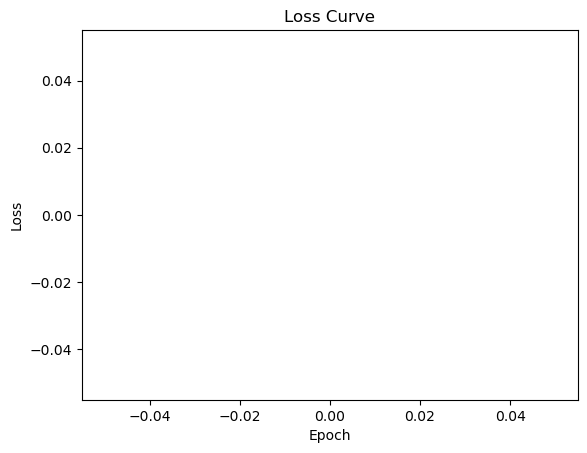

Epoch: 1, Loss: 1.838211800671804 + 0.0im
Epoch: 2, Loss: 1.2528058714587922 + 0.0im
Epoch: 3, Loss: 0.7829402505633485 + 0.0im
Epoch: 4, Loss: 0.8129537832182997 + 0.0im
Epoch: 5, Loss: 0.8117813745055229 + 0.0im
Epoch: 6, Loss: 0.6986375588935906 + 0.0im
Epoch: 7, Loss: 0.6427521400512186 + 0.0im
Epoch: 8, Loss: 0.6869705544144713 + 0.0im
Epoch: 9, Loss: 0.7267056555438975 + 0.0im
Epoch: 10, Loss: 0.7086127382502394 + 0.0im
Epoch: 11, Loss: 0.6668273670640569 + 0.0im
Epoch: 12, Loss: 0.6463704089755489 + 0.0im
Epoch: 13, Loss: 0.6238230892152626 + 0.0im
Epoch: 14, Loss: 0.5999607443954538 + 0.0im
Epoch: 15, Loss: 0.5962273465172366 + 0.0im
Epoch: 16, Loss: 0.5926876100066498 + 0.0im
Epoch: 17, Loss: 0.582089262347188 + 0.0im
Epoch: 18, Loss: 0.5568954390082833 + 0.0im
Epoch: 19, Loss: 0.5369892377202682 + 0.0im
Epoch: 20, Loss: 0.5246644083924626 + 0.0im
Epoch: 21, Loss: 0.5256513108050457 + 0.0im
Epoch: 22, Loss: 0.5212320791298312 + 0.0im
Epoch: 23, Loss: 0.5055107272241036 + 0.0im

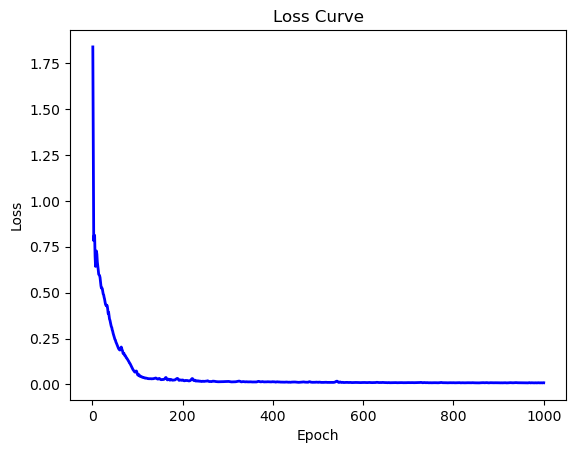

In [7]:
train(opt,layers,x,t,D,epochs=1000)

In [8]:
opt.α=0.05

0.05

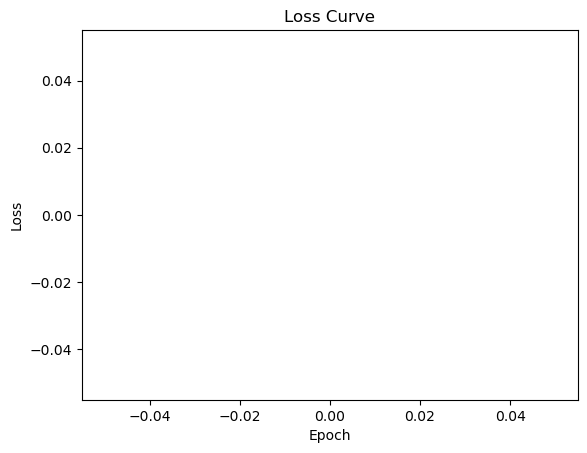

Epoch: 1, Loss: 0.008567788922148862 + 0.0im
Epoch: 2, Loss: 0.007911883391673435 + 0.0im
Epoch: 3, Loss: 0.008100696322266553 + 0.0im
Epoch: 4, Loss: 0.008730179504964039 + 0.0im
Epoch: 5, Loss: 0.009245966429504753 + 0.0im
Epoch: 6, Loss: 0.009610031928417747 + 0.0im
Epoch: 7, Loss: 0.009408652336933396 + 0.0im
Epoch: 8, Loss: 0.00925781211798945 + 0.0im
Epoch: 9, Loss: 0.009067155429908113 + 0.0im
Epoch: 10, Loss: 0.00880078555221541 + 0.0im
Epoch: 11, Loss: 0.008486525051904462 + 0.0im
Epoch: 12, Loss: 0.008397527207516105 + 0.0im
Epoch: 13, Loss: 0.00846622425331484 + 0.0im
Epoch: 14, Loss: 0.008692882610286492 + 0.0im
Epoch: 15, Loss: 0.008902169330338109 + 0.0im
Epoch: 16, Loss: 0.009275582594028145 + 0.0im
Epoch: 17, Loss: 0.008959770709205747 + 0.0im
Epoch: 18, Loss: 0.008770303865774471 + 0.0im
Epoch: 19, Loss: 0.008220819409866607 + 0.0im
Epoch: 20, Loss: 0.008622156271059288 + 0.0im
Epoch: 21, Loss: 0.008743301806183951 + 0.0im
Epoch: 22, Loss: 0.008496569496873458 + 0.0im


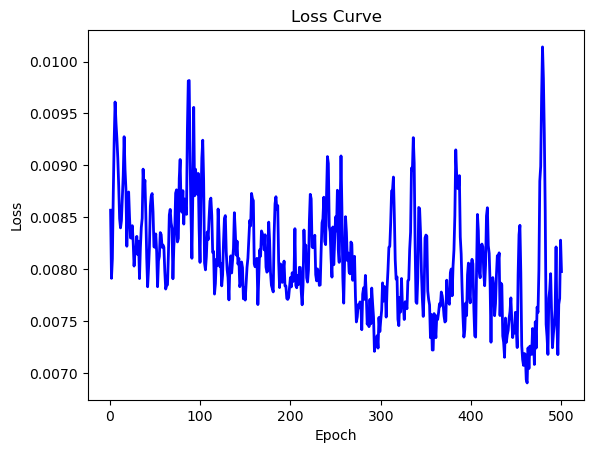

In [9]:
train(opt,layers,x,t,D,epochs=500)

In [10]:
opt.α=0.05

0.05